# Campaign Diagnostics Analysis & Profiling Report
**Run ID:** `20261025T121437Z_omarchy_e49038`  
**Protocol:** `campaign-diagnostics/1`  
**Workload:** Ribbon 1v1 Campaign (`ribbon_waves`), 8 matches, 79 turns, 142,279 candidates  
**Host:** AMD Ryzen 5 4600H (6 cores / 12 threads), Omarchy Linux x86-64, Julia 1.12.6  
**Gameplay SHA-256:** `34f5319d5a5bcfaec6a190178495c1fae33fa94088339156bdb6ced6c9b92503`

This notebook provides an in-depth visual and quantitative exploration of the diagnostic profiling data collected in run `20261025T121437Z_omarchy_e49038`, covering:
1. **CPU Profiling Breakdown** (Category distribution and function-level hotspots)
2. **Allocation Sources & Memory Attribution** (Identifying major allocation contributors)
3. **Scaling Performance & Parallel Efficiency** across 1, 2, 4, and 8 worker processes
4. **Phase Instrumentation Overhead** (Impact of timer instrumentation)
5. **Memory Footprint & RSS Dynamics** (Loaded, warmed, post-campaign, and peak memory)
6. **Workload Balance & Critical Path Analysis** (Per-match analysis explaining scaling limits)

In [1]:
import json
import tarfile
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Setup paths robustly
repo_root = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
run_dir = repo_root / "results" / "diagnostics" / "runs" / "20261025T121437Z_omarchy_e49038"
tar_path = repo_root / "results" / "diagnostics" / "artifacts" / "20261025T121437Z_omarchy_e49038.tar.gz"

print(f"Repository Root: {repo_root}")
print(f"Run Directory: {run_dir} (exists: {run_dir.exists()})")
print(f"Tarball Path: {tar_path} (exists: {tar_path.exists()})")

# Load structured datasets
trials_df = pd.read_csv(run_dir / "trials.csv")
processes_df = pd.read_csv(run_dir / "processes.csv")
with open(run_dir / "diagnostics.json") as f:
    diagnostics_json = json.load(f)
with open(run_dir / "manifest.json") as f:
    manifest_json = json.load(f)

# Configure plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans, Arial, Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e0e0e0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

Repository Root: /home/kurapica/Projects/pevo/julia_clone
Run Directory: /home/kurapica/Projects/pevo/julia_clone/results/diagnostics/runs/20261025T121437Z_omarchy_e49038 (exists: True)
Tarball Path: /home/kurapica/Projects/pevo/julia_clone/results/diagnostics/artifacts/20261025T121437Z_omarchy_e49038.tar.gz (exists: True)


---
## 1. CPU Profile Breakdown

The one-worker CPU profile recorded **13,813 primary-thread samples** at a 10 ms sampling interval without filling the buffer.
Samples are attributed to exclusive categories using the deepest recognized stack frame.

Key finding: In earlier throughput measurements, simulation appeared to take ~98.9% of phase time. However, profiling reveals that **broad-phase filtering only represents ~20.0%** of simulation time, while **precise collision and physics represents 43.3%**, **scoring and events represents 18.7%**, and **engine updates represent 17.7%**.

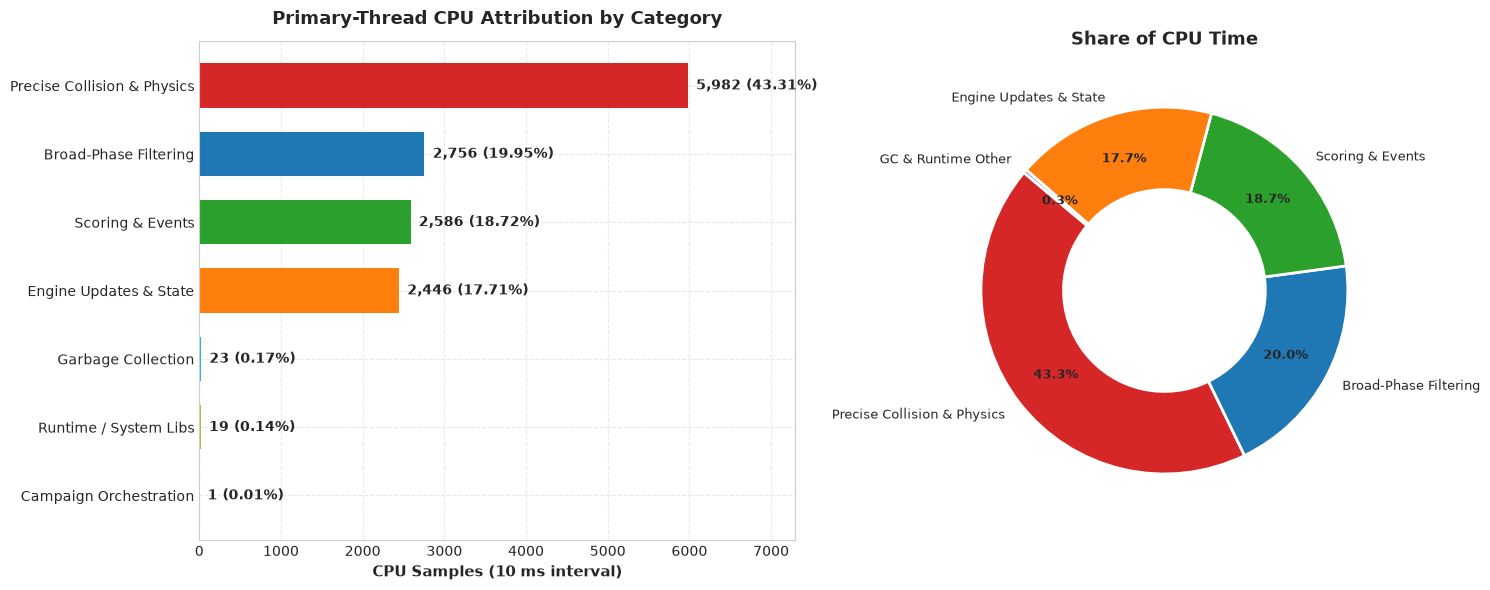

In [2]:
# Extract CPU Category Breakdown
cpu_entry = next(e for e in diagnostics_json if e['kind'] == 'cpu')
cpu_trial = cpu_entry['trials'][0]
samples_by_cat = cpu_trial['cpu']['samples_by_category']
total_samples = cpu_trial['cpu']['samples']

cat_df = pd.DataFrame(list(samples_by_cat.items()), columns=['Category', 'Samples'])
cat_df['Percentage'] = cat_df['Samples'] / total_samples * 100
cat_df = cat_df.sort_values('Samples', ascending=True)

# Format category labels for display
label_map = {
    'precise_collision_and_physics': 'Precise Collision & Physics',
    'broad_phase': 'Broad-Phase Filtering',
    'scoring_and_events': 'Scoring & Events',
    'engine_updates': 'Engine Updates & State',
    'gc': 'Garbage Collection',
    'runtime_or_other': 'Runtime / System Libs',
    'campaign_and_reset': 'Campaign Orchestration'
}
cat_df['DisplayName'] = cat_df['Category'].map(label_map).fillna(cat_df['Category'])

# Plot Horizontal Bar & Donut Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.3, 1]})

# Horizontal Bar Chart
colors = ['#7f7f7f', '#bcbd22', '#17becf', '#ff7f0e', '#2ca02c', '#1f77b4', '#d62728']
bars = ax1.barh(cat_df['DisplayName'], cat_df['Samples'], color=colors[-len(cat_df):], edgecolor='none', height=0.65)
ax1.set_xlabel('CPU Samples (10 ms interval)', fontsize=11, fontweight='bold')
ax1.set_title('Primary-Thread CPU Attribution by Category', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlim(0, max(cat_df['Samples']) * 1.22)

for bar, pct, count in zip(bars, cat_df['Percentage'], cat_df['Samples']):
    ax1.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
             f"{count:,} ({pct:.2f}%)", va='center', ha='left', fontsize=10, fontweight='bold')

# Donut Chart for High-Level Proportions
major_cats = cat_df[cat_df['Samples'] > 50].sort_values('Samples', ascending=False)
other_samples = cat_df[cat_df['Samples'] <= 50]['Samples'].sum()
if other_samples > 0:
    major_cats = pd.concat([major_cats, pd.DataFrame([{'DisplayName': 'GC & Runtime Other', 'Samples': other_samples}])])

donut_colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd']
wedges, texts, autotexts = ax2.pie(
    major_cats['Samples'],
    labels=major_cats['DisplayName'],
    autopct='%1.1f%%',
    pctdistance=0.75,
    startangle=140,
    colors=donut_colors[:len(major_cats)],
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')
for t in texts:
    t.set_fontsize(9)
ax2.set_title('Share of CPU Time', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

### Function-Level Hotspot Analysis

By inspecting stack traces from `cpu-stacks.jsonl` inside the raw artifact archive, we examine which core PeggleSim functions contribute most to CPU samples.

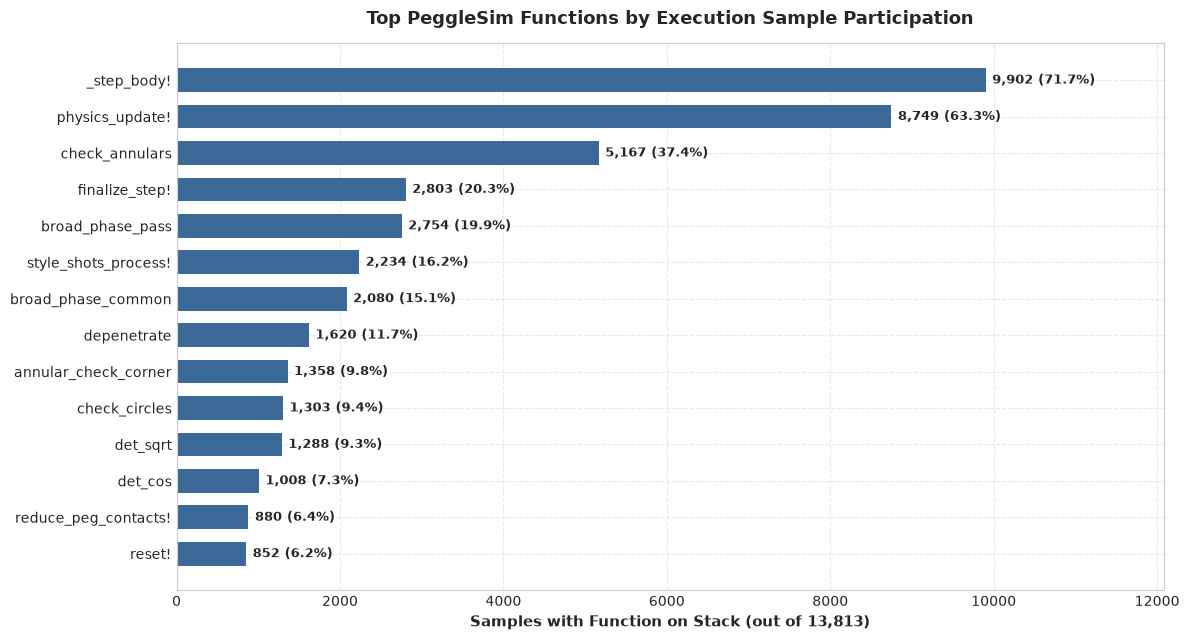

In [3]:
# Extract function stack participations from cpu-stacks.jsonl
from collections import Counter

function_samples = Counter()
with tarfile.open(tar_path) as tar:
    f = tar.extractfile('cpu-w1/profile-r1/cpu-stacks.jsonl')
    for line in f:
        d = json.loads(line)
        frames = d['stack'].split(';')
        cnt = d['count']
        seen = set()
        for fr in frames:
            if 'PeggleSim' in fr:
                fn = fr.split('@')[0]
                if fn and not fn.startswith('macro') and not fn.startswith('#') and fn not in ('trial', 'run_campaign', 'run_bot_game', 'evaluate_candidates!', 'main', 'run_shot!', 'update!', 'step_simulation!'):
                    seen.add(fn)
        for fn in seen:
            function_samples[fn] += cnt

fn_df = pd.DataFrame(function_samples.most_common(14), columns=['Function', 'Samples'])
fn_df['Percent'] = fn_df['Samples'] / total_samples * 100
fn_df = fn_df.sort_values('Samples', ascending=True)

plt.figure(figsize=(12, 6.5))
bars = plt.barh(fn_df['Function'], fn_df['Samples'], color='#3b6998', edgecolor='none', height=0.65)
plt.xlabel('Samples with Function on Stack (out of 13,813)', fontsize=11, fontweight='bold')
plt.title('Top PeggleSim Functions by Execution Sample Participation', fontsize=13, fontweight='bold', pad=14)
plt.xlim(0, max(fn_df['Samples']) * 1.22)

for bar, pct, count in zip(bars, fn_df['Percent'], fn_df['Samples']):
    plt.text(bar.get_width() + 80, bar.get_y() + bar.get_height()/2,
             f"{count:,} ({pct:.1f}%)", va='center', ha='left', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 2. Allocation Sources & Memory Attribution

While individual shot simulations were qualified with **strict zero allocation** in Milestone 4, the full 1v1 campaign allocates **~2,017 MiB** across 79 turns and 142,279 candidates.

The allocation profiler sampled **132,009 events at a 0.01 sampling rate**. The data below reveals why the campaign allocates memory:
- **`Peg` instantiation during checkpoint restoration** at `level.jl:41` generates **76.7%** of sampled bytes.
- **Base64 decoding of RNG state during checkpoint restoration** at `checkpoint.jl:872` generates **13.6%** of sampled bytes.
- Candidate evaluation in the bot loop restores from checkpoint before each aim evaluation (1,801 candidates per turn), incurring peg allocations and base64 parsing 142,279 times!

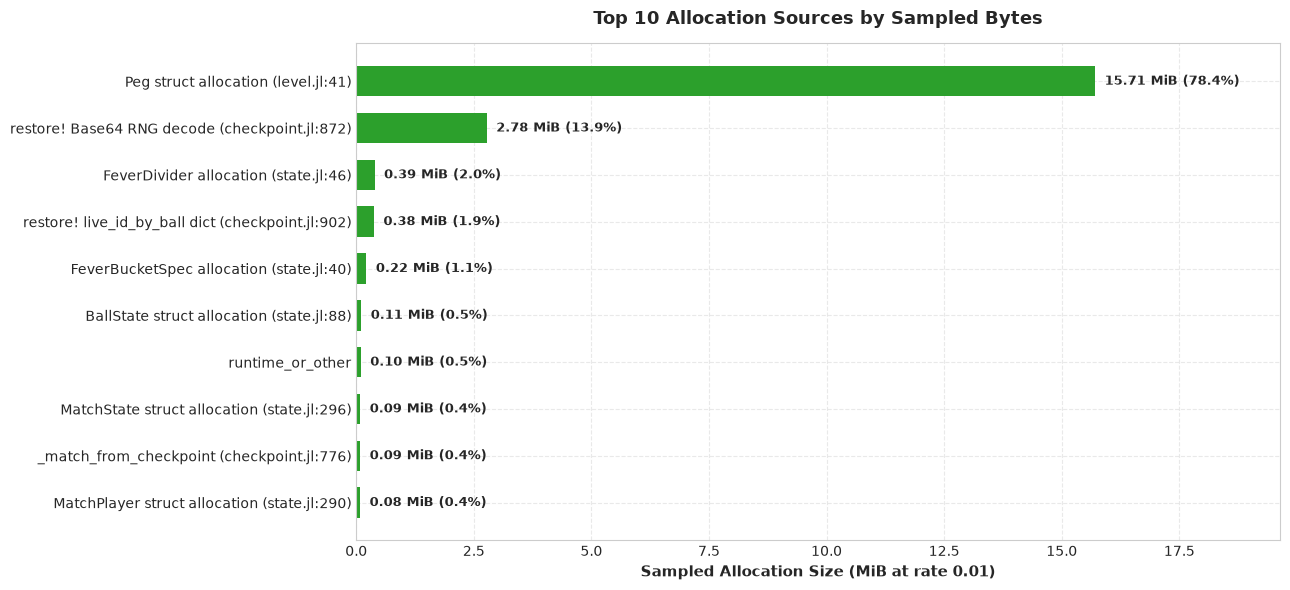

In [4]:
# Extract Allocation Sites from diagnostics.json
alloc_entry = next(e for e in diagnostics_json if e['kind'] == 'allocations')
alloc_trial = alloc_entry['trials'][0]
alloc_sites = alloc_trial['allocations']['sampled_bytes_by_site']
total_sampled_bytes = sum(alloc_sites.values())

top_sites = sorted(alloc_sites.items(), key=lambda x: x[1], reverse=True)[:10]
sites_df = pd.DataFrame(top_sites, columns=['Site', 'SampledBytes'])
sites_df['SampledMiB'] = sites_df['SampledBytes'] / (1024**2)
sites_df['Percent'] = sites_df['SampledBytes'] / total_sampled_bytes * 100

# Shorten site labels for plotting
def clean_site_name(s):
    if 'Peg at level.jl' in s:
        return 'Peg struct allocation (level.jl:41)'
    elif 'checkpoint.jl:872' in s:
        return 'restore! Base64 RNG decode (checkpoint.jl:872)'
    elif 'FeverDivider' in s:
        return 'FeverDivider allocation (state.jl:46)'
    elif 'checkpoint.jl:902' in s:
        return 'restore! live_id_by_ball dict (checkpoint.jl:902)'
    elif 'FeverBucketSpec' in s:
        return 'FeverBucketSpec allocation (state.jl:40)'
    elif 'BallState' in s:
        return 'BallState struct allocation (state.jl:88)'
    elif 'MatchState' in s:
        return 'MatchState struct allocation (state.jl:296)'
    elif '_match_from_checkpoint' in s:
        return '_match_from_checkpoint (checkpoint.jl:776)'
    elif 'MatchPlayer' in s:
        return 'MatchPlayer struct allocation (state.jl:290)'
    return s[:45]

sites_df['Label'] = sites_df['Site'].apply(clean_site_name)
sites_df = sites_df.sort_values('SampledBytes', ascending=True)

plt.figure(figsize=(13, 6))
bars = plt.barh(sites_df['Label'], sites_df['SampledMiB'], color='#2ca02c', edgecolor='none', height=0.65)
plt.xlabel('Sampled Allocation Size (MiB at rate 0.01)', fontsize=11, fontweight='bold')
plt.title('Top 10 Allocation Sources by Sampled Bytes', fontsize=13, fontweight='bold', pad=14)
plt.xlim(0, max(sites_df['SampledMiB']) * 1.25)

for bar, pct, mib in zip(bars, sites_df['Percent'], sites_df['SampledMiB']):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f"{mib:.2f} MiB ({pct:.1f}%)", va='center', ha='left', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 3. Worker Scaling & Parallel Efficiency

The benchmark compares 1, 2, 4, and 8 active match worker processes. Each worker count was evaluated across 3 paired repetitions (with phase instrumentation alternating True/False).

### Timing Metrics & Scaling Table

 workers   wall_med   wall_min   wall_max  candidates_per_sec  speedup  efficiency_pct
       1 149.513755 146.919581 149.873178          951.611443 1.000000      100.000000
       2  80.787659  80.663308  81.471444         1761.147694 1.850700       92.535021
       4  45.648244  45.522397  46.834765         3116.855927 3.275345       81.883629
       8  34.422003  34.327630  37.736928         4133.373702 4.343552       54.294399


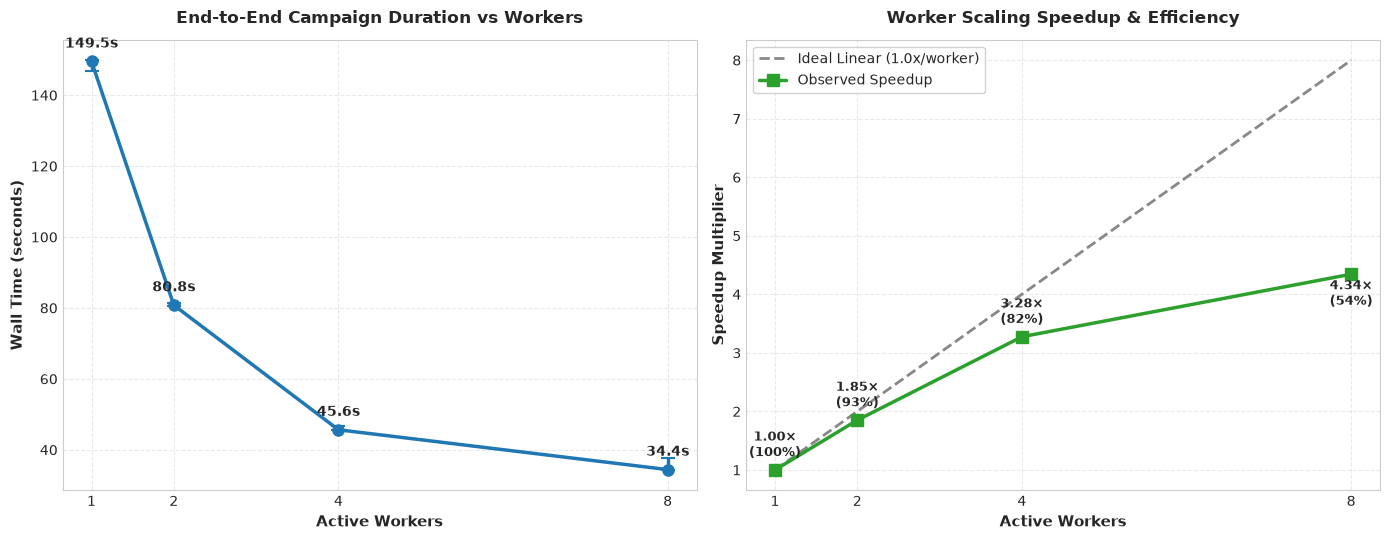

In [5]:
timing_trials = trials_df[trials_df['kind'] == 'timing'].copy()

# Group by worker count and instrumentation
scaling_summary = timing_trials.groupby(['workers', 'phase_instrumentation']).agg(
    wall_med=('wall_seconds', 'median'),
    wall_min=('wall_seconds', 'min'),
    wall_max=('wall_seconds', 'max'),
    sim_med=('campaign_setup_and_simulation_seconds', 'median'),
    gc_s_med=('gc_seconds', 'median'),
    gc_colls_med=('gc_collections', 'median'),
    alloc_mib_med=('allocated_bytes', lambda s: np.median(s) / (1024**2))
).reset_index()

# Extract uninstrumented (False) baseline for speedup calculation
uninst = scaling_summary[scaling_summary['phase_instrumentation'] == False].copy()
base_time = uninst[uninst['workers'] == 1]['wall_med'].values[0]
uninst['speedup'] = base_time / uninst['wall_med']
uninst['efficiency_pct'] = (uninst['speedup'] / uninst['workers']) * 100
uninst['candidates_per_sec'] = 142279 / uninst['wall_med']

print(uninst[['workers', 'wall_med', 'wall_min', 'wall_max', 'candidates_per_sec', 'speedup', 'efficiency_pct']].to_string(index=False))

# Plot Wall Time & Speedup
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

workers = uninst['workers'].values
wall_med = uninst['wall_med'].values
wall_err_neg = wall_med - uninst['wall_min'].values
wall_err_pos = uninst['wall_max'].values - wall_med

# Wall Time Curve
ax1.errorbar(workers, wall_med, yerr=[wall_err_neg, wall_err_pos], fmt='-o', color='#1f77b4',
             linewidth=2.5, markersize=8, capsize=5, capthick=1.5, label='Campaign Wall Time')
ax1.set_xlabel('Active Workers', fontsize=11, fontweight='bold')
ax1.set_ylabel('Wall Time (seconds)', fontsize=11, fontweight='bold')
ax1.set_title('End-to-End Campaign Duration vs Workers', fontsize=12, fontweight='bold', pad=12)
ax1.set_xticks(workers)
ax1.grid(True)
for w, t in zip(workers, wall_med):
    ax1.annotate(f"{t:.1f}s", (w, t), textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold')

# Speedup Curve vs Ideal Linear
ax2.plot(workers, workers, '--', color='#888888', linewidth=2, label='Ideal Linear (1.0x/worker)')
ax2.plot(workers, uninst['speedup'], '-s', color='#2ca02c', linewidth=2.5, markersize=8, label='Observed Speedup')
ax2.set_xlabel('Active Workers', fontsize=11, fontweight='bold')
ax2.set_ylabel('Speedup Multiplier', fontsize=11, fontweight='bold')
ax2.set_title('Worker Scaling Speedup & Efficiency', fontsize=12, fontweight='bold', pad=12)
ax2.set_xticks(workers)
ax2.set_yticks(range(1, 9))
ax2.legend(frameon=True, facecolor='white', framealpha=0.9)
ax2.grid(True)

for w, sp, eff in zip(workers, uninst['speedup'], uninst['efficiency_pct']):
    ax2.annotate(f"{sp:.2f}×\n({eff:.0f}%)", (w, sp), textcoords="offset points",
                 xytext=(0, -22 if w == 8 else 10), ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 4. Phase Instrumentation Overhead Analysis

Phase timers record candidate reset, selection, simulation, actual shot execution, and checkpointing. `run_campaign` allows disabling phase instrumentation via `phase_instrumentation=false`.

In each worker setting, 3 paired repetitions alternated enabled and disabled instrumentation.
- At 1, 2, and 4 workers, median timer overhead is **0.22% to 1.29%**, with paired spreads spanning both positive and negative values (dominated by normal run-to-run noise).
- At 8 workers, overhead is consistently positive (**median 2.48%**, range 1.08% to 3.07%), reflecting timer system calls and synchronization over shorter total execution times.

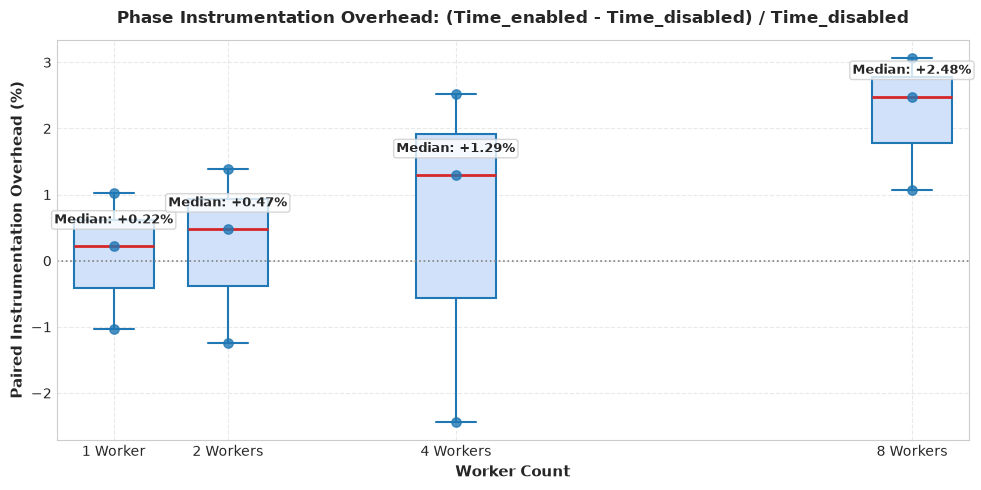

In [6]:
# Compute paired overheads
paired_records = []
for w in [1, 2, 4, 8]:
    w_df = timing_trials[timing_trials['workers'] == w]
    for r in [1, 2, 3]:
        t_true = w_df[(w_df['repeat'] == r) & (w_df['phase_instrumentation'] == True)]['wall_seconds'].values[0]
        t_false = w_df[(w_df['repeat'] == r) & (w_df['phase_instrumentation'] == False)]['wall_seconds'].values[0]
        pct = (t_true - t_false) / t_false * 100
        paired_records.append({'workers': w, 'repeat': r, 'overhead_pct': pct})

overhead_df = pd.DataFrame(paired_records)

# Plot overhead distribution
plt.figure(figsize=(10, 5))
worker_groups = [overhead_df[overhead_df['workers'] == w]['overhead_pct'].values for w in [1, 2, 4, 8]]
box = plt.boxplot(worker_groups, positions=[1, 2, 4, 8], widths=0.7, patch_artist=True,
                  boxprops=dict(facecolor='#d0e1f9', color='#1f77b4', linewidth=1.5),
                  medianprops=dict(color='#d62728', linewidth=2),
                  whiskerprops=dict(color='#1f77b4', linewidth=1.5),
                  capprops=dict(color='#1f77b4', linewidth=1.5))

# Add scatter points for individual pairs
for w in [1, 2, 4, 8]:
    pts = overhead_df[overhead_df['workers'] == w]['overhead_pct'].values
    plt.scatter([w]*len(pts), pts, color='#1f77b4', s=45, zorder=3, alpha=0.8)

plt.axhline(0, color='gray', linestyle=':', linewidth=1.2)
plt.xlabel('Worker Count', fontsize=11, fontweight='bold')
plt.ylabel('Paired Instrumentation Overhead (%)', fontsize=11, fontweight='bold')
plt.title('Phase Instrumentation Overhead: (Time_enabled - Time_disabled) / Time_disabled', fontsize=12, fontweight='bold', pad=12)
plt.xticks([1, 2, 4, 8], ['1 Worker', '2 Workers', '4 Workers', '8 Workers'])

# Annotate medians
for w in [1, 2, 4, 8]:
    med = overhead_df[overhead_df['workers'] == w]['overhead_pct'].median()
    plt.text(w, med + 0.35, f"Median: {med:+.2f}%", ha='center', fontsize=9.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#cccccc', alpha=0.8))

plt.tight_layout()
plt.show()

---
## 5. Memory Footprint & Real-Time RSS Dynamics

Each worker setting ran in a fresh Julia process with 8 default threads, 0 interactive threads, and `--gcthreads=1`.
RSS was sampled externally by the parent Python process every 100 ms to avoid perturbing worker execution.

The memory metrics capture:
- **Loaded RSS (~594–604 MiB):** Baseline memory after loading packages and interchange definitions.
- **Warmed RSS (~612–672 MiB):** Memory after executing initial warmups and JIT compilation.
- **Post-Campaign RSS (~611–683 MiB):** Memory immediately following campaign completion before process exit.
- **Sampled Campaign Peak (~655–732 MiB):** Highest RSS observed during measured campaign execution.
- **Process Lifetime Peak (~655–734 MiB):** Cumulative maximum including load, JIT compilation, and warmups.

 Workers  Loaded RSS (MiB)  Warmed RSS (MiB)  Post-Campaign RSS (MiB)  Sampled Peak (MiB)  Lifetime Peak (MiB)
       1        598.808594        611.792969               611.500000          654.847656           654.585938
       2        594.296875        640.417969               666.171875          710.675781           710.632812
       4        603.710938        629.546875               662.285156          708.714844           734.000000
       8        601.242188        672.312500               683.265625          731.843750           731.281250


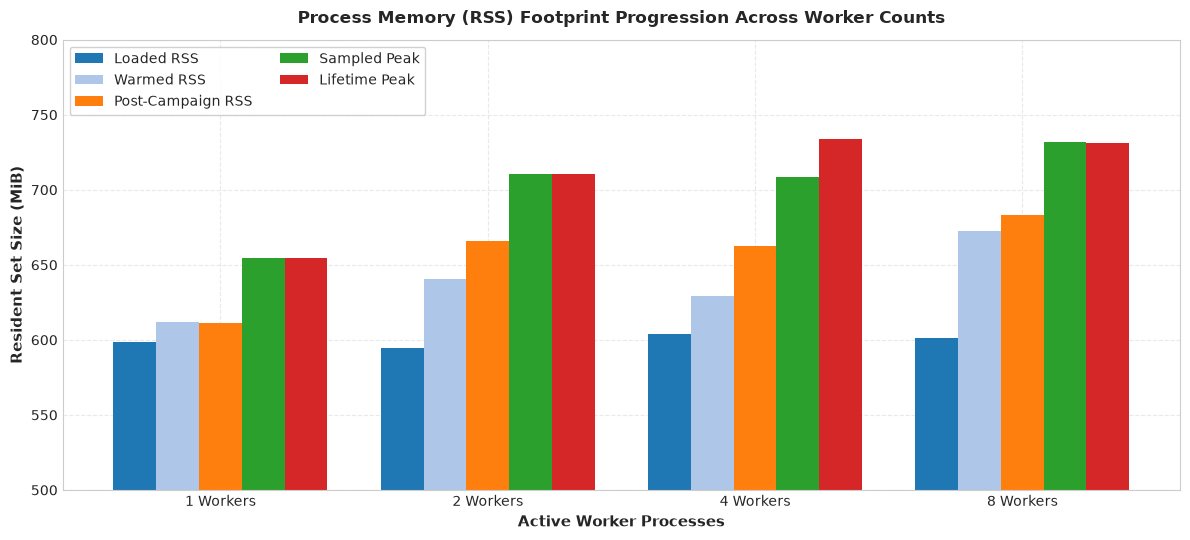

In [7]:
# Extract Memory Table
mem_records = []
for w in [1, 2, 4, 8]:
    proc_row = processes_df[(processes_df['kind'] == 'timing') & (processes_df['workers'] == w)].iloc[0]
    trials_w = timing_trials[timing_trials['workers'] == w]
    mem_records.append({
        'Workers': w,
        'Loaded RSS (MiB)': proc_row['loaded_rss_bytes'] / (1024**2),
        'Warmed RSS (MiB)': proc_row['warmed_rss_bytes'] / (1024**2),
        'Post-Campaign RSS (MiB)': trials_w['post_campaign_rss_bytes'].max() / (1024**2),
        'Sampled Peak (MiB)': trials_w['sampled_campaign_peak_rss_bytes'].max() / (1024**2),
        'Lifetime Peak (MiB)': trials_w['process_lifetime_peak_rss_bytes'].max() / (1024**2)
    })

mem_df = pd.DataFrame(mem_records)
print(mem_df.to_string(index=False))

# Grouped Bar Chart of Memory Stages
fig, ax = plt.subplots(figsize=(12, 5.5))
bar_width = 0.16
x = np.arange(len(mem_df['Workers']))

stages = [('Loaded RSS (MiB)', '#1f77b4'),
          ('Warmed RSS (MiB)', '#aec7e8'),
          ('Post-Campaign RSS (MiB)', '#ff7f0e'),
          ('Sampled Peak (MiB)', '#2ca02c'),
          ('Lifetime Peak (MiB)', '#d62728')]

for i, (col, color) in enumerate(stages):
    offset = (i - 2) * bar_width
    bars = ax.bar(x + offset, mem_df[col], width=bar_width, label=col.replace(' (MiB)', ''), color=color, edgecolor='none')

ax.set_xlabel('Active Worker Processes', fontsize=11, fontweight='bold')
ax.set_ylabel('Resident Set Size (MiB)', fontsize=11, fontweight='bold')
ax.set_title('Process Memory (RSS) Footprint Progression Across Worker Counts', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels([f"{w} Workers" for w in mem_df['Workers']])
ax.set_ylim(500, 800)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, ncol=2)

plt.tight_layout()
plt.show()

### Real-Time RSS Timeline During Campaign Execution

Extracting the 100 ms external RSS samples from `timing-w1-rss.csv` and `timing-w8-rss.csv` illustrates memory stability during continuous execution.

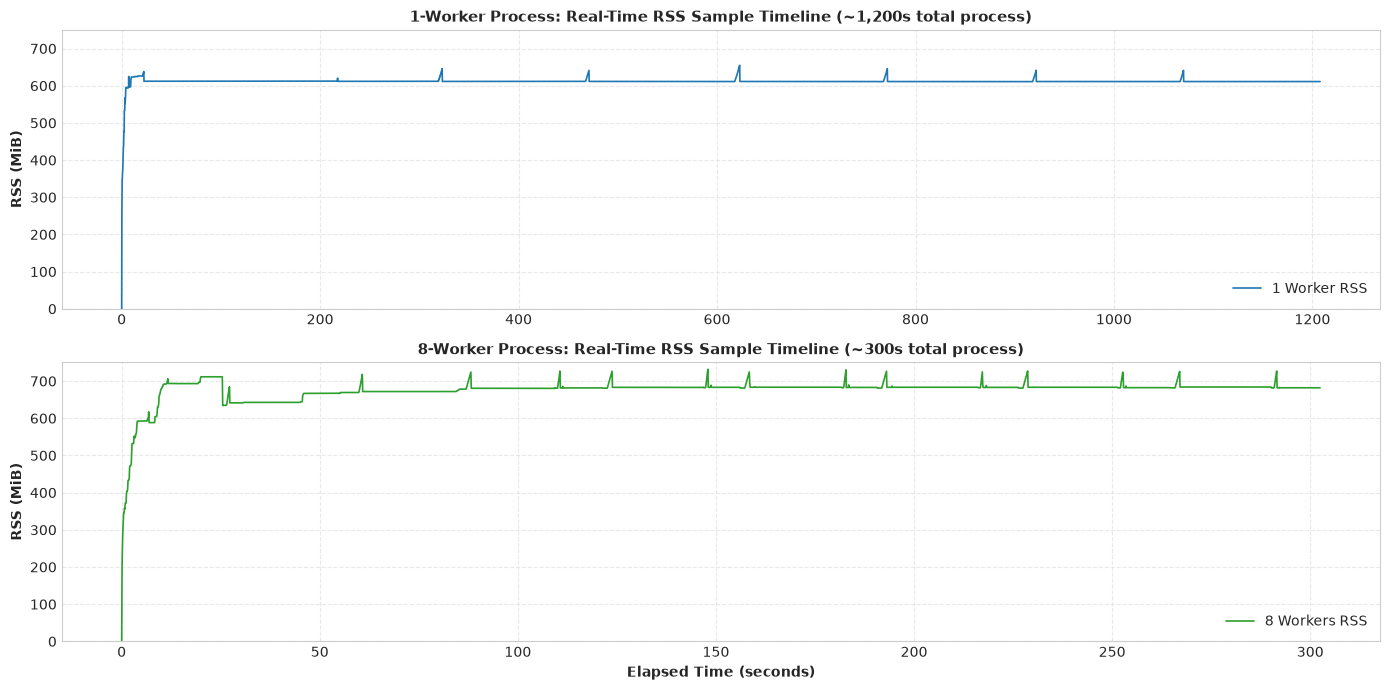

In [8]:
# Extract time-series RSS samples from tarball
w1_rss_df = None
w8_rss_df = None
with tarfile.open(tar_path) as tar:
    f1 = tar.extractfile('timing-w1-rss.csv')
    w1_rss_df = pd.read_csv(f1)
    f8 = tar.extractfile('timing-w8-rss.csv')
    w8_rss_df = pd.read_csv(f8)

w1_rss_df['rss_mib'] = w1_rss_df['rss_bytes'] / (1024**2)
w8_rss_df['rss_mib'] = w8_rss_df['rss_bytes'] / (1024**2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharey=True)

# 1-Worker Process Timeline
ax1.plot(w1_rss_df['elapsed_seconds'], w1_rss_df['rss_mib'], color='#1f77b4', linewidth=1.2, label='1 Worker RSS')
ax1.set_title('1-Worker Process: Real-Time RSS Sample Timeline (~1,200s total process)', fontsize=11, fontweight='bold')
ax1.set_ylabel('RSS (MiB)', fontsize=10, fontweight='bold')
ax1.set_ylim(0, 750)
ax1.grid(True)
ax1.legend(loc='lower right')

# 8-Worker Process Timeline
ax2.plot(w8_rss_df['elapsed_seconds'], w8_rss_df['rss_mib'], color='#2ca02c', linewidth=1.2, label='8 Workers RSS')
ax2.set_title('8-Worker Process: Real-Time RSS Sample Timeline (~300s total process)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Elapsed Time (seconds)', fontsize=10, fontweight='bold')
ax2.set_ylabel('RSS (MiB)', fontsize=10, fontweight='bold')
ax2.grid(True)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

---
## 6. Workload Imbalance & Scaling Bottleneck (Critical Path Analysis)

Why does parallel scaling plateau from 4 workers (3.28× speedup, 81.9% efficiency) to 8 workers (4.34× speedup, 54.3% efficiency)?

The workload consists of **eight seeded matches** executed via match-level parallelism (one Julia task per match).
Because the simulation stops once a match finishes (e.g. Red Cleared vs Balls Exhausted), the matches have widely differing turn counts and candidate evaluations:
- **Match 7** lasts **20 turns** and evaluates **36,020 candidates**, taking **26.37 seconds** of simulation time alone.
- **Match 5** lasts only **6 turns** and evaluates **10,806 candidates**, taking **12.50 seconds** of simulation time.

At 8 workers, 7 workers finish their matches early and idle while waiting for the single worker executing Match 7.
Under Amdahl's Law, the minimum campaign time cannot fall below the critical path of Match 7 (~26.4s + setup/teardown), creating a theoretical upper bound on speedup of ~5.6× for this 8-match workload.

  Match  Turns  Candidates  Simulation_s   Winner
Match 1      7       12607     20.360424 Player 2
Match 2     10       18010     19.664725 Player 1
Match 3      8       14408     14.215299 Player 2
Match 4      9       16209     15.922538 Player 1
Match 5      6       10806     12.499830 Player 2
Match 6     11       19811     18.336468 Player 1
Match 7     20       36020     26.366994 Player 1
Match 8      8       14408     19.041681 Player 2


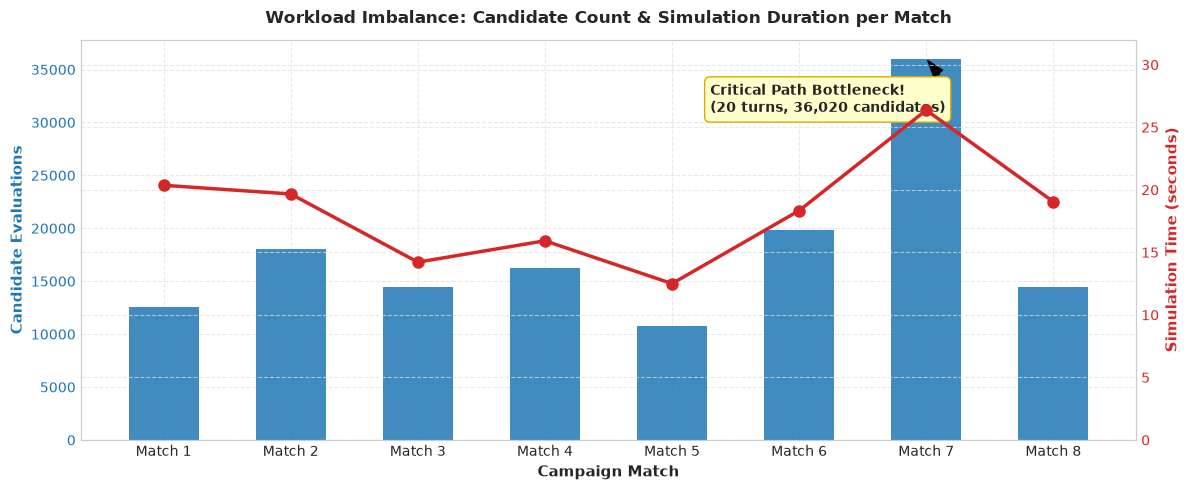

In [9]:
# Extract per-match timings and candidates from history
with tarfile.open(tar_path) as tar:
    f = tar.extractfile('timing-w1/history-r1-true.json')
    history_data = json.load(f)

match_timings = history_data['timings']
match_games = history_data['games']

match_records = []
for i, (t, g) in enumerate(zip(match_timings, match_games)):
    match_records.append({
        'Match': f"Match {i+1}",
        'Turns': len(g.get('decisions', [])),
        'Candidates': t.get('candidates', 0),
        'Simulation_s': t['phases']['simulation'],
        'Winner': f"Player {g.get('winner')}"
    })

match_df = pd.DataFrame(match_records)
print(match_df.to_string(index=False))

# Plot Candidates and Simulation Time per Match
fig, ax1 = plt.subplots(figsize=(12, 5))

x = np.arange(len(match_df['Match']))
bars1 = ax1.bar(x, match_df['Candidates'], color='#1f77b4', alpha=0.85, width=0.55, label='Candidates Evaluated')
ax1.set_xlabel('Campaign Match', fontsize=11, fontweight='bold')
ax1.set_ylabel('Candidate Evaluations', color='#1f77b4', fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.set_xticks(x)
ax1.set_xticklabels(match_df['Match'])

# Overlay simulation time on secondary axis
ax2 = ax1.twinx()
line2 = ax2.plot(x, match_df['Simulation_s'], color='#d62728', marker='o', linewidth=2.5, markersize=8, label='Simulation Time (s)')
ax2.set_ylabel('Simulation Time (seconds)', color='#d62728', fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#d62728')
ax2.set_ylim(0, 32)

plt.title('Workload Imbalance: Candidate Count & Simulation Duration per Match', fontsize=12, fontweight='bold', pad=12)

# Annotate the Match 7 critical path
ax1.annotate('Critical Path Bottleneck!\n(20 turns, 36,020 candidates)',
             xy=(6, match_df.loc[6, 'Candidates']),
             xytext=(4.3, 31000),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', facecolor='#ffffcc', edgecolor='#ddaa00'))

plt.tight_layout()
plt.show()

---
## 7. Key Findings & Strategic Optimization Opportunities

Based on this diagnostic profiling run, five key optimization pathways emerge:

1. **Eliminate Peg Reallocation & Base64 Decoding in Checkpoint Restoration:**
   - `restore!` currently pushes brand new `Peg` mutable structs into `e.pegs` and decodes base64 strings on every candidate evaluation.
   - **Recommendation:** Implement in-place peg field copying and cache decoded RNG bytes. This will eliminate ~90% of the campaign's 2,017 MiB heap allocation and reduce memory churn.

2. **Optimize Annular Peg Narrow-Phase Collision Checking:**
   - `check_annulars` participates in **37.4%** of CPU samples (`annular_check_corner`, `annular_check_cap`, and `annular_is_inside_arc`).
   - **Recommendation:** Fast bounding-box/bounding-circle rejection specifically tailored for annular arcs before evaluating exact corner intersections and trigonometry.

3. **Transcendental Math Vectorization / Fast Deterministic Math:**
   - Deterministic math functions (`det_sqrt`, `det_cos`, `det_sin`, `det_atan2`) account for **~26%** of stack sample frames.
   - **Recommendation:** Inline vector distance calculations and examine memoized trigonometric tables or fast approximations compatible with the deterministic CORE-MATH requirement.

4. **Fine-Grained Dynamic Work Scheduling:**
   - Match-level parallelism suffers from severe straggler effects due to Match 7 taking 26.4s while Match 5 takes 12.5s.
   - **Recommendation:** Chunked candidate sweeps or task-stealing at the turn or candidate level to maintain 100% core saturation across all 8 cores.

5. **Style Shot Event Processing Overhead:**
   - `style_shots_process!` takes **16.2%** of CPU samples during `finalize_step!`.
   - **Recommendation:** Short-circuit style shot tracking during bot candidate evaluations where style points do not alter bot shot selection.